In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [2]:
# load the pharmacy dataset
df = pd.read_csv("global_pharmacy_sales_2020_2025_daily_dataset.csv")

# convert date column into date format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# remove rows where date or sales information is missing
df = df.dropna(subset=["date", "units_sold", "unit_price"])

# calculate total sales value for each medicine record
df["sales_value"] = df["units_sold"] * df["unit_price"]

# combine all medicine records for each date
daily = df.groupby("date")["sales_value"].sum()

# arrange dates in chronological order
daily = daily.sort_index()

# fill any missing calendar dates
daily = daily.asfreq("D")
daily = daily.interpolate(method="time")

print("First date:", daily.index.min())
print("Last date:", daily.index.max())
print("Total daily records:", len(daily))
print(daily.head())

First date: 2020-01-01 00:00:00
Last date: 2025-12-31 00:00:00
Total daily records: 2192
date
2020-01-01    3069325.55
2020-01-02    3792212.65
2020-01-03    2579306.04
2020-01-04    2674030.68
2020-01-05    3004000.06
Freq: D, Name: sales_value, dtype: float64


count    2.192000e+03
mean     1.911867e+06
std      6.986374e+05
min      8.769667e+05
25%      1.367911e+06
50%      1.801978e+06
75%      2.232893e+06
max      4.362441e+06
Name: sales_value, dtype: float64


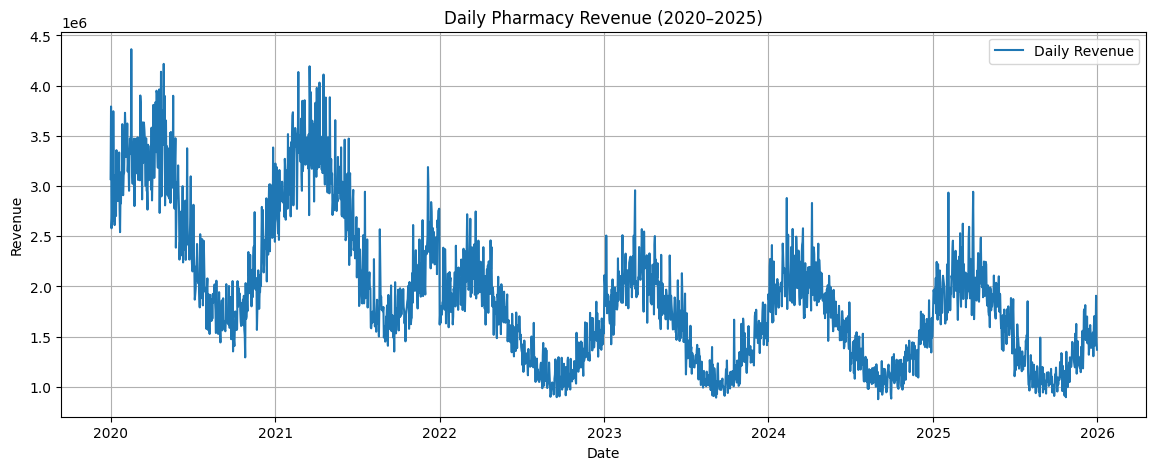

In [3]:
# display basic statistical information
print(daily.describe())

# plot daily revenue over time
plt.figure(figsize=(14, 5))
plt.plot(daily, label="Daily Revenue")

plt.title("Daily Pharmacy Revenue (2020–2025)")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True)
plt.show()

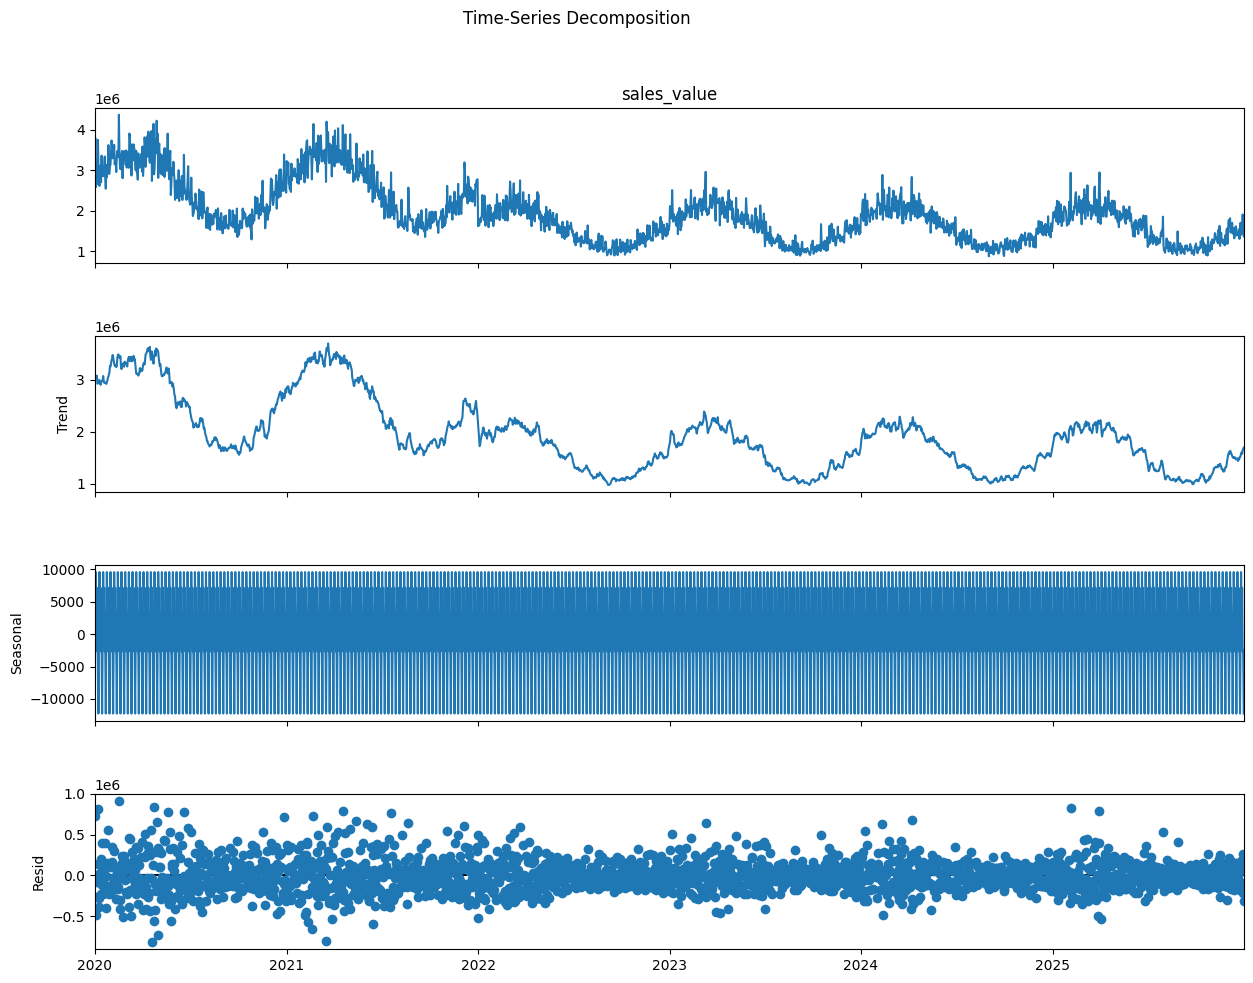

In [4]:
# decompose the series into its main components
result = seasonal_decompose(
    daily,
    model="additive",
    period=7,
    extrapolate_trend="freq"
)

# display all decomposition components
result.plot()
plt.gcf().set_size_inches(14, 10)
plt.suptitle("Time-Series Decomposition", y=1.02)
plt.show()

Average seasonal effect:
Monday       -2672.11
Tuesday      -2432.46
Wednesday   -12272.97
Thursday     -1778.85
Friday        9600.65
Saturday      2380.82
Sunday        7174.93
Name: seasonal, dtype: float64


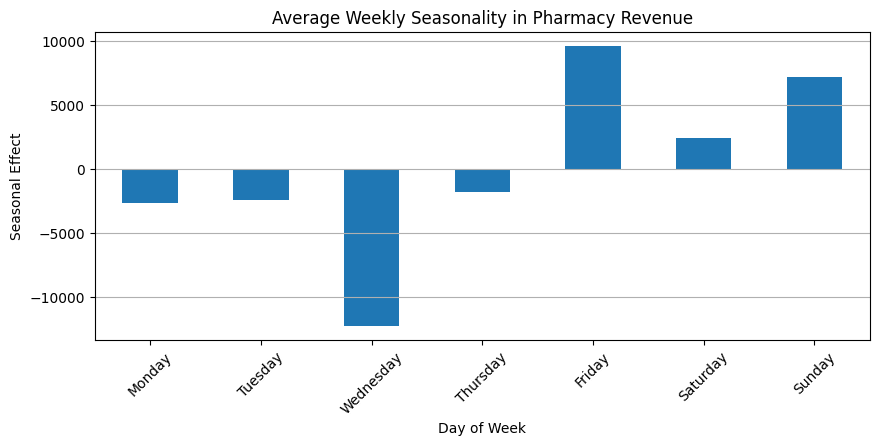

In [5]:
# calculate average seasonal effect for each day
seasonal_effect = result.seasonal.groupby(
    result.seasonal.index.dayofweek
).mean()

# give names to weekdays
seasonal_effect.index = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

print("Average seasonal effect:")
print(seasonal_effect.round(2))

# display the weekly pattern
seasonal_effect.plot(kind="bar", figsize=(10, 4))

plt.title("Average Weekly Seasonality in Pharmacy Revenue")
plt.xlabel("Day of Week")
plt.ylabel("Seasonal Effect")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

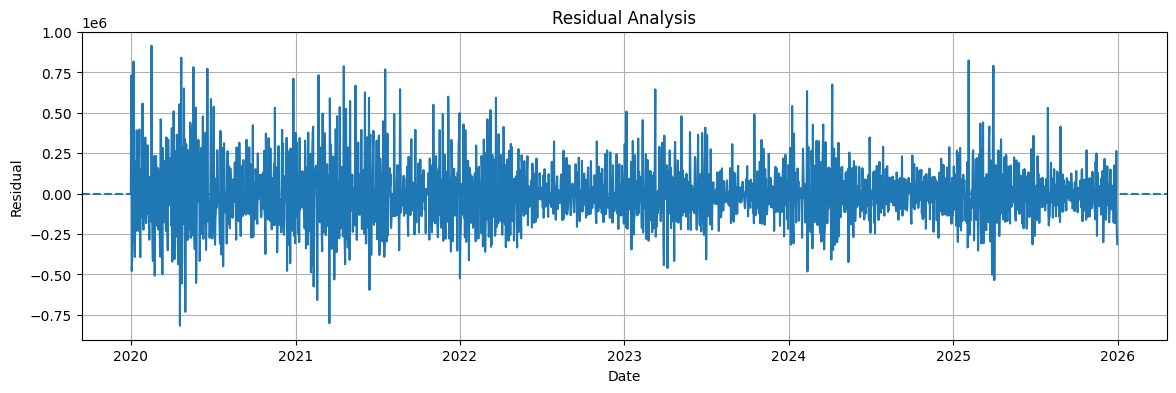

Mean residual: -168.18
Residual standard deviation: 192279.37


In [6]:
# extract residual values
residuals = result.resid.dropna()

# plot residuals over time
plt.figure(figsize=(14, 4))
plt.plot(residuals)

plt.title("Residual Analysis")
plt.xlabel("Date")
plt.ylabel("Residual")
plt.axhline(0, linestyle="--")
plt.grid(True)
plt.show()

# display residual statistics
print("Mean residual:", round(residuals.mean(), 2))
print("Residual standard deviation:", round(residuals.std(), 2))

In [7]:
# store forecasting results and error scores
scores = []
forecasts = []

# test the model on three different years
for year in [2023, 2024, 2025]:

    # use only dates before the test year for training
    train = daily[daily.index.year < year]

    # keep the selected year for testing
    test = daily[daily.index.year == year]

    # build the forecasting model
    model = ExponentialSmoothing(
        train,
        trend="add",
        seasonal="add",
        seasonal_periods=7,
        initialization_method="estimated"
    )

    # train the model
    fitted_model = model.fit(optimized=True)

    # forecast the complete test period
    pred = fitted_model.forecast(len(test))

    # calculate forecasting errors
    mae = mean_absolute_error(test, pred)
    rmse = np.sqrt(mean_squared_error(test, pred))

    # calculate MAPE safely
    non_zero = test != 0
    mape = (
        np.mean(
            np.abs(
                (test[non_zero] - pred[non_zero])
                / test[non_zero]
            )
        ) * 100
    )

    # save the evaluation scores
    scores.append({
        "Test Year": year,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

    # save actual and predicted values
    forecasts.append(pd.DataFrame({
        "Actual": test,
        "Forecast": pred,
        "Test Year": year
    }))

# combine the results
score_table = pd.DataFrame(scores)

print("Forecast Validation Results:")
print(score_table.round(2).to_string(index=False))

Forecast Validation Results:
 Test Year       MAE       RMSE  MAPE (%)
      2023 865604.01 1043992.92     67.36
      2024 864966.77 1033819.40     67.01
      2025 989949.91 1206789.20     78.28
